# Crack-tip stress fields from MD dump trajectories

Ti₂N MXene, armchair sheet at 300 K, central crack with a Ti-tip, 2a = 27.72 Å.

This notebook shows how I turned the per-atom stress dumps from my LAMMPS fracture simulations into the stress contours used in my thesis. I show a single case here. For the thesis the same procedure is repeated for every crack length, tip geometry and temperature.

In [1]:
import mmap
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree
from IPython.display import Image

case = Path(r"data/Ti2N_armchair/300k/27.72A_Ntip")
dump = case / "dump.stress.lammpstrj"

crack_len = 27.72      # 2a, angstrom
thickness = 2.29       # monolayer thickness used for the atomic volume, angstrom
bar_to_gpa = 1e-4
vmax = 65              # top of the colour scale, GPa
gap = 0.95             # cells farther than gap*bond length from any atom are drawn white

### 1. Reading the dump trajectory

The stress dump is several GB, so I do not load it whole. I scan it once for the byte position of every `ITEM: TIMESTEP` block, then read only the frame I need and only four columns: atom type, x, y and the time-averaged per-atom stress `f_ave_atom[1]` (the σxx component).

In [2]:
def index_dump(path):
    steps, offsets = [], []
    with open(path, "rb") as f, mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ) as mm:
        pos = mm.find(b"ITEM: TIMESTEP")
        while pos != -1:
            nl = mm.find(b"\n", pos)
            end = mm.find(b"\n", nl + 1)
            steps.append(int(mm[nl + 1:end]))
            offsets.append(pos)
            pos = mm.find(b"ITEM: TIMESTEP", end)
    return np.array(steps), offsets


def read_frame(path, offset, col="f_ave_atom[1]"):
    with open(path, "rb") as f:
        f.seek(offset)
        for _ in range(3):
            f.readline()
        n = int(f.readline())
        f.readline()
        xlo, xhi = map(float, f.readline().split()[:2])
        ylo, yhi = map(float, f.readline().split()[:2])
        f.readline()
        names = f.readline().decode().split()[2:]
        use = [names.index(c) for c in ("type", "x", "y", col)]
        atoms = np.loadtxt(f, usecols=use, max_rows=n)
    lx, ly = xhi - xlo, yhi - ylo
    vol = lx * ly * thickness / n                    # volume per atom
    sigma = atoms[:, 3] * bar_to_gpa / vol           # bar*A^3 -> GPa
    return atoms[:, 1], atoms[:, 2], sigma, lx, ly


steps, offsets = index_dump(dump)
print(f"{len(steps)} frames, steps {steps[0]} to {steps[-1]}")

### 2. Finding the onset of crack propagation

In [3]:
ss = np.genfromtxt(case / "stress_strain.txt", names=True)

smooth = np.convolve(np.pad(ss["sigmaxx"], 1, mode="edge"), np.ones(3) / 3, mode="valid")
peak_step = ss["step"][smooth.argmax()]
onset = np.searchsorted(steps, peak_step)

def strain_at(k):
    return 100 * np.interp(steps[k], ss["step"], ss["strain"])

print(f"peak stress {smooth.max():.1f} GPa at step {peak_step}")
print(f"onset frame {onset} (strain {strain_at(onset):.2f} %)")

### 3. From per-atom stress to a contour

LAMMPS gives stress times volume per atom. I divide by the atomic volume (box area × thickness / number of atoms) and convert bar to GPa. The atoms are then binned onto a fine grid and averaged with a Gaussian window, which removes the lattice-scale thermal speckle.

In [4]:
def field(frame, n=700):
    x, y, s, lx, ly = frame
    if lx < ly:                         # put the long side horizontal
        x, y = y, -x
    x, y = x - x.min(), y - y.min()
    W, H = x.max(), y.max()
    nb = (n, max(int(n * H / W), 1))
    rng = [[0, W], [0, H]]

    S = np.histogram2d(x, y, nb, rng, weights=s)[0]
    C = np.histogram2d(x, y, nb, rng)[0]
    sm = 1.5 * np.sqrt(W * H / len(x)) / (W / n)     # ~1.5 atom spacings, in grid cells
    f = gaussian_filter(S, sm) / np.maximum(gaussian_filter(C, sm), 1e-9)

    # leave cells white where no atom is close by (open crack, free edges)
    pts = np.c_[x, y]
    tree = cKDTree(pts)
    bond = np.median(tree.query(pts, k=2)[0][:, 1])  # typical nearest-neighbour distance
    gx = (np.arange(nb[0]) + 0.5) * W / nb[0]
    gy = (np.arange(nb[1]) + 0.5) * H / nb[1]
    grid = np.stack(np.meshgrid(gx, gy, indexing="ij"), -1).reshape(-1, 2)
    dist = tree.query(grid)[0].reshape(nb)
    f[dist > gap * bond] = np.nan
    return f.T, W, H


cmap = plt.get_cmap("jet").copy()
cmap.set_bad("white")
norm = PowerNorm(0.45, vmin=0, vmax=vmax)
ticks = [0, 10, 25, 45, 65]

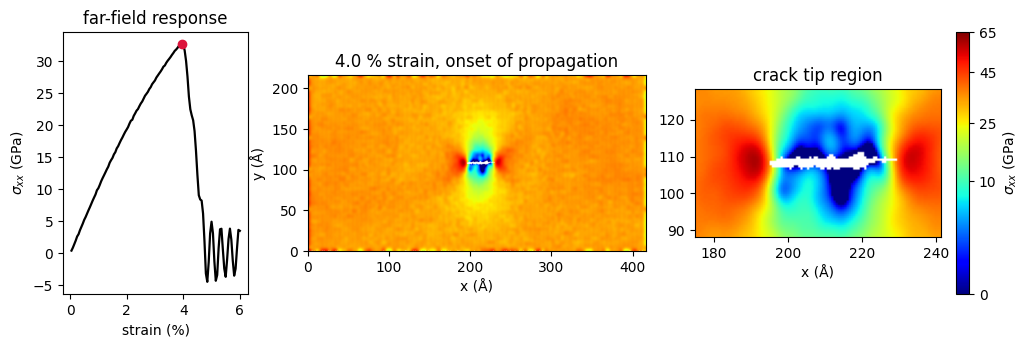

In [5]:
f, W, H = field(read_frame(dump, offsets[onset]))
cx, cy = W / 2, H / 2
hw = 1.2 * crack_len                    # half width of the zoom window

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), gridspec_kw={"width_ratios": [1, 2.2, 1.6]})

ax[0].plot(100 * ss["strain"], ss["sigmaxx"], lw=1.6, color="k")
ax[0].plot(strain_at(onset), np.interp(steps[onset], ss["step"], ss["sigmaxx"]), "o", color="crimson")
ax[0].set(xlabel="strain (%)", ylabel=r"$\sigma_{xx}$ (GPa)", title="far-field response")

for a in ax[1:]:
    im = a.imshow(f, origin="lower", extent=(0, W, 0, H), cmap=cmap, norm=norm)
    a.set_xlabel("x (Å)")
ax[1].set_ylabel("y (Å)")
ax[1].set_title(f"{strain_at(onset):.1f} % strain, onset of propagation")
ax[2].set(xlim=(cx - hw, cx + hw), ylim=(cy - 0.6 * hw, cy + 0.6 * hw), title="crack tip region")

fig.colorbar(im, ax=ax[1:], ticks=ticks, pad=0.02, label=r"$\sigma_{xx}$ (GPa)")
plt.savefig("onset_contour.png", dpi=200, bbox_inches="tight")
plt.show()

### 4. Crack propagation

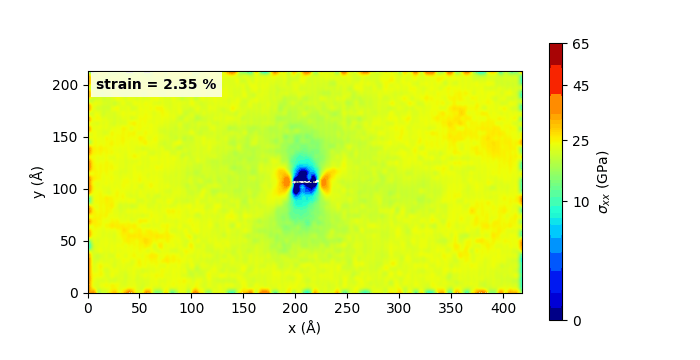

In [6]:
frames = np.unique(np.linspace(int(0.6 * onset), len(steps) - 1, 40).astype(int))

fig, ax = plt.subplots(figsize=(7, 3.6))
f, W, H = field(read_frame(dump, offsets[frames[0]]))
im = ax.imshow(f, origin="lower", extent=(0, W, 0, H), cmap=cmap, norm=norm)
tag = ax.text(0.02, 0.92, "", transform=ax.transAxes, fontweight="bold",
              bbox=dict(fc="white", ec="none", alpha=0.8))
ax.set(xlabel="x (Å)", ylabel="y (Å)")
fig.colorbar(im, ticks=ticks, label=r"$\sigma_{xx}$ (GPa)")

def update(k):
    im.set_data(field(read_frame(dump, offsets[k]))[0])
    tag.set_text(f"strain = {strain_at(k):.2f} %")

FuncAnimation(fig, update, frames=frames).save("crack_propagation.gif", writer=PillowWriter(fps=8))
plt.close(fig)
Image(filename="crack_propagation.gif")